In [1]:
# Homework 2: Ordinary differential equations
# Due October 29, 2026
# Alex Feucht
# ASTR 427 - Professor Quinn Fall 2026 UW Seattle Campus
#
# AI Disclosure:
# Claude/Gemini search engine results used for general debugging and querying of 
# python package documentation/syntax, no generative uses permitted.

In [2]:
# Imports - Using Scipy package for integration method(s)

import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp # default reference ODE solver package

In [3]:
# 1. Write a program (or programs) to integrate a set of an arbitrary number
# of coupled differential equations using the Euler method, fourth order
# Runge-Kutta, and Leapfrog. (Note: Leapfrog only applies to special
# cases.) For Runge-Kutta, you may use a packaged routine such as
# available in scipy or Numerical Recipes. If you do used a packaged
# routine, be sure to use one with a fixed timestep and order so
# that testing the convergence can be easily performed.

In [4]:
# 1.a)
# Euler Method
#
# y_(n+1) = y_n + hf(x_n, y_n)
# 
# Error of order O(h^3), function of order 1
# Naive solution, but useful in other integration methods that are not 
# self-starting, like Leapfrog. Other higher order methods should out-perform.
#
# NOTE: For all intents and purposes throughout this coding assignment
# h = (t_end - t_0) / N number of intervals, and N = (t_end - t_0) / h,
# are reciprocal functions of one another dependent on the time/step interval
# N*h = the total elapsed time
# I will be using both interchangably as the unit conversions are required
#
# All Integration Methods in this code have been parameterized equally to
# accept the same inputs and produce the same output, in terms of variables
# f = Arbitrary function
# y_0 = starting position
# t_0 = starting timestamp
# t_end = ending timestamp
# N = number of intervals, typically the node count is N + 1, one-off error,
# which I do address within the linspace or other function params to end
# on the final node exactly to avoid extraneous endpoint behaviors

def Euler(f, y_0, t_0, t_end, N):
    h =  (t_end - t_0) / N # unit conversion to interval time, ~dt
    t = np.linspace(t_0, t_end, N + 1) # sets the timestamp array of equal dt
    y = np.zeros((N + 1, len(y_0))) # initializes y array of 0's to populate
    # Crucially, the sizes of t and y must have the same dimensions
    # but must be transposed in order to be evaluated, N x M = M x N
    
    y[0] = y_0 # Sets start point of Euler Method
    
    for i in range(N): # for index over entire number of intervals
        # i'th interval + 1 is the prior interval, plus the passed function
        # definition evaluated at that pairwise f(t, y) input * time duration
        # Here, we pass the basic dx/dt derivative function to get slope tangent
        y[i + 1] = y[i] + (h * f(t[i], y[i]))
        
    return t, y # returns tabulated position values at time intervals

In [5]:
# 1.b)
# Fourth order Runge-Kutta
# 
# y_1 = y_0 + k_1/6 + k_2/3 + k_3/3 + k_4/6 + O(h^5)
# 
# Where k_n are as follows:
# k_1 = h(f(t_0, y_0))
# k_2 = h(f((t_1/2), (y_0 + k_1/2)))
# k_3 = h(f((t_1/2), (y_0 + k_2/2)))
# k_4 = h(f(t_1, (y_0 + k_3)))
#
# Independent t_0, dependent y_0
# Using scipy package, RK45, which uses both 4th and 5th order approximations
# in tandem, with the integration being 4th order and error terms of O(h^5)
# Not expected to have high accuracy, default scipy ODE solver, but stable
# in terms of symplectic drift of error correction terms, won't fluctuate out of
# control like Euler Method or some other integration methods often can.
# Extension of midpoint method, derivative extrapolaton of midpoint derivative.
# Very sensitive to endpoint behavior, be careful in tuning of accuracy params.
# Imperative to have final time step land on end point of last interval of h.

# RK45 Scipy package
# Default Scipy integration solver for ODE's, using solve_ivp
# rtol = relative tolerance, atol = absolute tolerance, applied at every step
# Internally, package caps tolerances based on max_step size, takes over from
# given tolerances when RMS(root mean square) over position interval > 1,
# iterating at smaller tolerances until normalized at RMS < 1

def RK45(f, y_0, t_0, t_end, N): # standardized input, see Euler's Method above
    t_grid = np.linspace(t_0, t_end, N + 1) # Same time interval as above

    # Takes input to RK45 in my standard params, accepts and uses to build scipy
    # given arbitrary f(), full timescale, position, RK45 inbuilt method,
    # and the scaled t_eval and max step with some baseline tolerances set.
    sol = solve_ivp(f, (t_0, t_end), y_0, method='RK45', t_eval=t_grid, 
                    max_step=((t_end - t_0) / N), rtol=1e-3, atol=1e-6)
    t = sol.t # tabulated timestamp
    y = np.transpose(sol.y) # transposed tabulated position values
    assert sol.success, sol.message # Error handling within package
    
    return t, y # returns tabulated position values at time intervals

In [6]:
# 1.c)
# Leapfrog
# 
# (Kick -> drift -> kick)
# x_(t+1/2) = x_t + h/2(f(v_t)) = [v_t + h(g(x_(t+1/2))]
# v_(t+1) = [v_t + h(g(x_(t+1/2)))]  <------/
# x_(t+1) = x_(t+1/2) + h/2(f(v_(t+1))) 
# 
# (Drift -> kick -> drift) (reverses time direction, symmetric point sampling)
# v_(t+1/2) = v_(t+1) - h/2(g(x_(t+1)))
# x_t = x_(t+1) - h(f(v_(t+1/2)))
# v_t = v_(t+1/2) - h/2(g(x_t))
# 
# Kick, drift, kick or drift, kick, drift integration method over variable
# half-steps, can reverse time direction and is excellent in cases of preserving
# symmetries and conserved quantities, such as gravitational potential or energy
# should perform well in instances of ODE's where this is the case for small h.
# 2nd order accurate, errors of O(h^3) order, special cases generalize to the
# Hamiltonian for exact analytic solutions. Not self-starting, often uses one 
# Euler step to start it off, taking steps at h/2 intervals.

def Leapfrog(f, y_0, t_0, t_end, N): # Same standard params, time spacing, h/N
    t = np.linspace(t_0, t_end, N + 1)
    h = ((t_end - t_0) / N)
    y = np.zeros((N + 1, len(y_0)))
    y[0] = y_0

    # Initial Euler step to kickstart the Leapfrog method
    _, y_start = Euler(f, y_0, t_0, t_0 + h, 1) # only takes the y value, not t
    # Sets 2nd y pos. value as the final evaluated Euler position starting value
    y[1] = y_start[-1]
    
    for i in range(1, N): # loop over all intervals, N+1 nodes
        # Uses y[0] starting pos. to update y[2] from Euler start y[1] value
        # for i=1, y[i+1] = y[2], y[i-1] = y[0], y[i] = y[1], etc...
        y[i+1] = y[i-1] + 2*h*f(t[i], y[i]) 
        
    return t, y # returns tabulated position values at time intervals

In [7]:
# 2. Use your program to solve the differential equation for x(t):
# (d^2x) /
# (dt^2) + x = 0;
# with the initial conditions x(0) = 1, x′(0) = 0. (Prime indicates a
# derivative with respect to t.) Note that this has the analytical solution:
# x = cos(t)
#
# (a) Integrate the equation for 0 ≤ t ≤ 30 using each of the methods,
# and step sizes of 1, 0.3, 0.1, 0.03, and 0.01. Comment on the behavior
# of the solutions.
#
# (b) Plot log(|x_numerical(30) − x_exact(30)|) as a function of log(stepsize)
# and check for the expected convergence of the error term.

In [8]:
# d^2x/dt^2 + x = 0, x_0 = 1, x'_0 = 0
# Analytic solutions:
# x(t)   = -(d^2x / dt^2) = cos(t),        x(t) = y[0]
# x'(t)  = dx / dt        = -sin(t),      x'(t) = y[1]
# x''(t) = -cos(t)        = -x(t),       x''(t) = -y[0]
# x''(t) + x(t) = 0, -cos(t) + cos(t) = 0, -x + x = 0, -y[0] + y[0] = 0
# integrating over x' = dx/dt gives velocity v, x'' gives acceleration a

def f(t, y): # double differentiation for this particular arbitrary function

    dxdt = y[1]
    dvdt = -y[0]
    
    return np.array([dxdt, dvdt], dtype=float) # returns x'(t), x''(t)

In [9]:
# 2.a) 
# Method dictionary
methods = {"Euler": Euler, "RK45": RK45, "Leapfrog": Leapfrog} 

h_1 = 1.0 # various h step size values, over 30 intervals, N + 1 nodes
h_2 = 0.3 # N = 30/0.3 = 100
h_3 = 0.1 # N = 30/0.1 = 300
h_4 = 0.03 # N = 30/0.03 = 1000
h_5 = 0.01 # N = 30/0.01 = 3000

h_span = np.array([h_1, h_2, h_3, h_4, h_5]) # array of h values
t_0 = 0.0 # initial time
t_end = 30.0 # end time

results = {name: {} for name in methods} # empty results container to populate

y_0 = np.array([1.0, 0.0], dtype='float') # initial (x, v) vals for x, dx/dt

for h in h_span: # nested for loop over all h values, over all methods
    N = int(round(((t_end - t_0)/h))) # truncation error prevention
    
    for name, method in methods.items(): # Using method dictionary Euler, RK45..
        t, y = method(f, y_0, t_0, t_end, N) # tabulates array for each method
        assert len(t) == N + 1 # N + 1 for end node after N steps, not off by 1
        results[name][N] = (t, y) # container for results array(time, y)
        # Stored for each method, over each N nodes per h time scale, used later

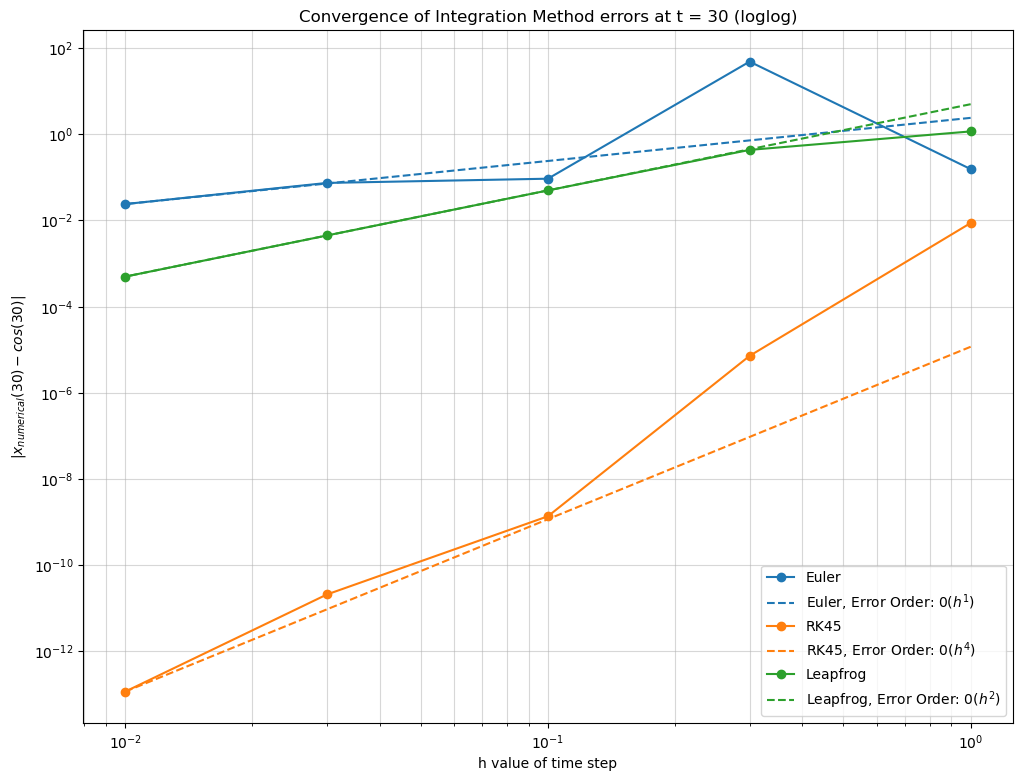

In [10]:
# 2.b) 
# Analytic function x(t) = cos(t)
# Plot to see how quickly each method approaches the analytic evaluation
# Accepts results arrays, over h values, against cos(t) analytic, given the
# expected/referenced error orders for each method, from lectures/NR3
def convergence_plot(results, h_span, x_analytic = np.cos, \
                     err_orders={"Euler": 1, "RK45": 4, "Leapfrog":2}):
    
    fig, ax = plt.subplots(figsize=(12,9)) # Basic matplotlib stuff to follow

    # Over all methods, calulate errors at each t and y interval
    for name, y_N in results.items():
        errors = np.array([abs(y[-1, 0] - x_analytic(t[-1])) \
                           for t, y in y_N.values()])
        
        line, = ax.loglog(h_span, errors, "o-", label=name) # line plots

        if name in err_orders: # uses dictionary O(h^n) to plot errors
            k = err_orders[name] # sets constant based on the above
            # loglog plot of error differences
            ax.loglog(h_span, errors[-1] * (h_span / h_span[-1])**k, "--", \
                      color=line.get_color(), alpha=1.0, \
                      label=f"{name}, Error Order: $0(h^{k})$")

    # more basic plotting, inside function def over all methods of integration
    ax.set_xlabel("h value of time step")
    ax.set_ylabel(r"$|x_{numerical}(30) - cos(30)|$")
    ax.set_title("Convergence of Integration Method errors at t = 30 (loglog)")
    ax.grid(True, which="both", alpha = 0.5)
    ax.legend()
    plt.show()

convergence_plot(results, h_span)

In [11]:
# 3. Now try the two dimensional orbit described by the potential:
# Φ = [(− 1) /
# √(1 + x^2 + y^2)] .
#
# From (d^2 ~r) /
# (dt^2) = −∇Φ, the orbits are given by the coupled differential equations:
#
# (d^2x) /
# (dt^2) = [(− x) /
# ((1 + x^2 + y^2)^(3/2))] ,
#
# (d^2y) /
# (dt^2) = [(− y) /
# ((1 + x^2 + y^2)^(3/2))] .
#
# (a) Integrate this for 0 ≤ t ≤ 100 for the initial conditions x = 1, y =
# 0, x′ = 0, y′ = 0.3. Try this with either Leapfrog or Runge-Kutta
# and step sizes from 0.01 to 1. Plot x vs. y for these integrations.
#
# (b) Plot the energy E = (x′^2 + y′^2)/2 + Φ(x, y) as a function of time
# for your integrations.
#
# (c) Integrate this same orbit (same force law and same initial condi-
# tions) for 0 ≤ t ≤ 100000 and a fixed step size of 0.4 with both
# Leapfrog and Runge-Kutta, and plot the energy, E, as a function
# of time for these integrations. Comment on the behavior of E(t)
# for these integrations, and the wall clock time each method took.

In [12]:
# Phi Orbital Potential Function Definition
# Initial Params setter
x_0 = 1.0
y_0 = 0.0
dx_0 = 0.0
dy_0 = 0.3

# initial_state = np.array([1.0, 0.0, 0.0, 0.3]) # 4 component 2nd order state
initial_state = np.array([x_0, y_0, dx_0, dy_0])

def phi_orbital_2D(t, initial_state): # function def for method integrators
        x, y, vx, vy = initial_state # local variable scope
        ax = -x / ((1.0 + x**2 + y**2)**(3/2)) # x coupled ODE
        ay = -y / ((1.0 + x**2 + y**2)**(3/2)) # y coupled ODE
    
        # updates initial positions as velocities, initial velocities as accels
        return np.array([vx, vy, ax, ay])

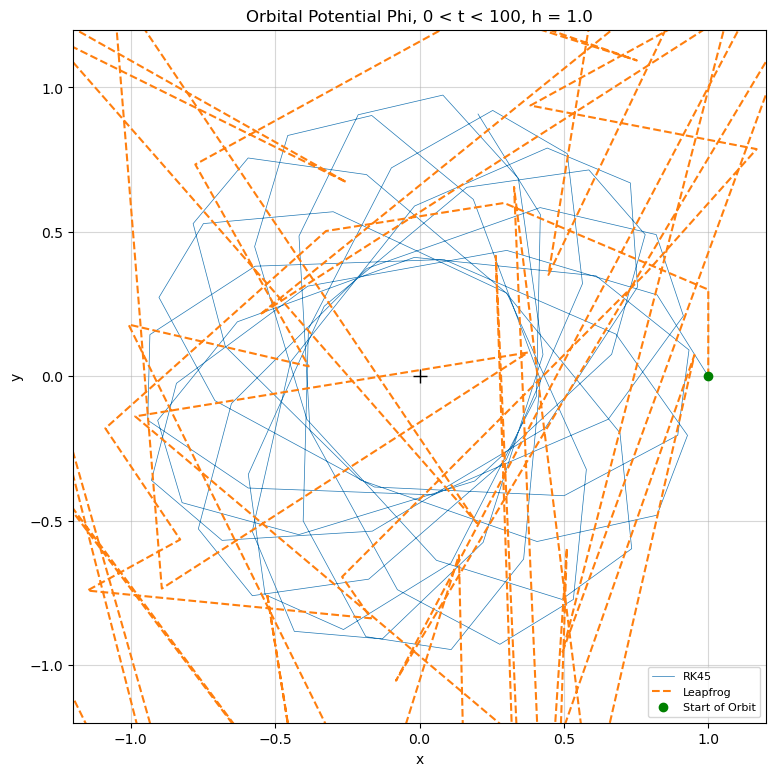

In [13]:
# 3.a) 
# Step Size 1.0

start_p = 0.0 # start and end of potential timestamps
end_p = 100.0
h_p = h_1 # interval value
N_p = int(round(((end_p - start_p)/h_p))) # truncation prevention
t_p = np.linspace(start_p, end_p, N_p+1) # 0 < t < 100, 0.01 h intervals

# Runge-Kutta: 
# RK45(f, y_0, t_0, t_end, N) params, returns RK(t, y), params defined above

t_RK, y_RK = RK45(phi_orbital_2D, initial_state, start_p, end_p, N_p)
assert len(t_RK) == N_p + 1 # N + 1 for end node after N steps, no off by 1
results_RK = (t_RK, y_RK) # container for results after funct calls
    

# Leapfrog: 
# # LF(f, y_0, t_0, t_end, N) params, returns LF(t, y), params defined above

t_LF, y_LF = Leapfrog(phi_orbital_2D, initial_state, start_p, end_p, N_p)
assert len(t_LF) == N_p + 1 # N + 1 for end node after N steps, no off by 1
results_RK = (t_LF, y_LF) # container for results after funct calls

# Plotting:
fig, ax = plt.subplots(figsize=(12,9)) # same size for all h interval plots
# This plotting is repeated 5 times in this and the 4 cells below
# Essentially, it plots every result array over the (t, y) values for both
# RK45 and Leapfrog result array tabulations. 
# Matplotlib formatting to see better, titles, legends, scaling etc...
# Nothing really differs between these 5 cells except h values at the top

ax.plot(y_RK[:, 0], y_RK[:,1], label="RK45", lw=0.5)
ax.plot(y_LF[:, 0], y_LF[:,1], "--", label="Leapfrog", lw=1.5)
ax.plot(0, 0, "k+", ms=10)
ax.plot(y_RK[0, 0], y_RK[0, 1], "go", ms=6, label="Start of Orbit")

ax.set_aspect("equal")
ax.set_xlim(-1.2, 1.2)
ax.set_ylim(-1.2, 1.2)
ax.set_xlabel("x")
ax.set_ylabel("y")
ax.set_title(f"Orbital Potential Phi, 0 < t < 100, h = {h_p}")
ax.grid(True, alpha=0.5)
ax.legend(fontsize=8, loc="lower right")
plt.show()


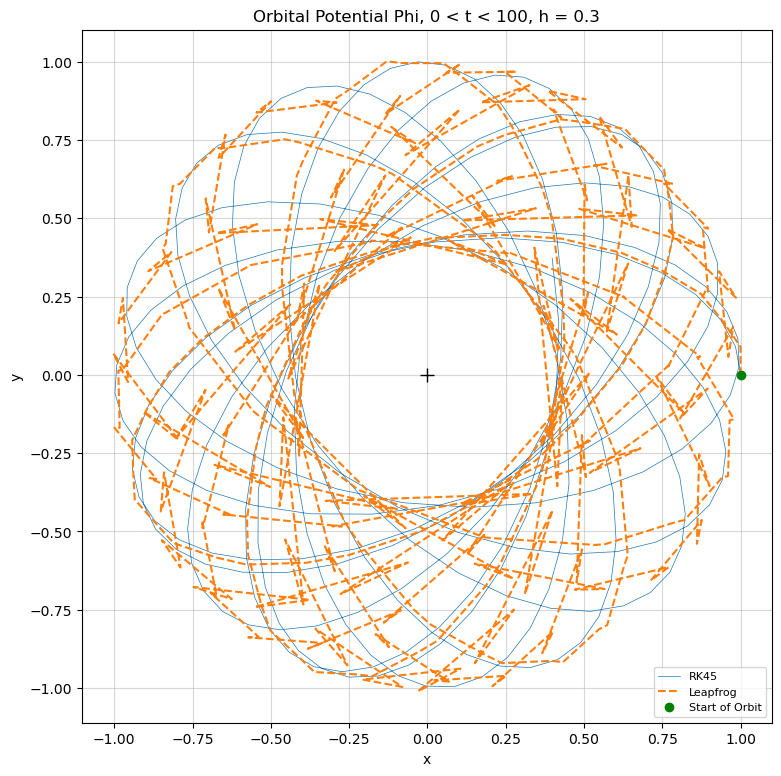

In [14]:
# 3.a) 
# Step Size 0.3

start_p = 0.0
end_p = 100.0
h_p = h_2 # interval value
N_p = int(round(((end_p - start_p)/h_p))) # truncation prevention
t_p = np.linspace(start_p, end_p, N_p+1) # 0 < t < 100, 0.01 h intervals

# Runge-Kutta: 
# (f, y_0, t_0, t_end, N) params, returns (t, y)

t_RK, y_RK = RK45(phi_orbital_2D, initial_state, start_p, end_p, N_p)
assert len(t_RK) == N_p + 1 # N + 1 for end node after N steps, no off by 1
results_RK = (t_RK, y_RK) # container for results after funct calls
    

# Leapfrog: 
# # (f, y_0, t_0, t_end, N) params, returns (t, y)

t_LF, y_LF = Leapfrog(phi_orbital_2D, initial_state, start_p, end_p, N_p)
assert len(t_LF) == N_p + 1 # N + 1 for end node after N steps, no off by 1
results_RK = (t_LF, y_LF) # container for results after funct calls

# Plotting:

fig, ax = plt.subplots(figsize=(12,9))

ax.plot(y_RK[:, 0], y_RK[:,1], label="RK45", lw=0.5)
ax.plot(y_LF[:, 0], y_LF[:,1], "--", label="Leapfrog", lw=1.5)
ax.plot(0, 0, "k+", ms=10)
ax.plot(y_RK[0, 0], y_RK[0, 1], "go", ms=6, label="Start of Orbit")

ax.set_aspect("equal")
ax.set_xlabel("x")
ax.set_ylabel("y")
ax.set_title(f"Orbital Potential Phi, 0 < t < 100, h = {h_p}")
ax.grid(True, alpha=0.5)
ax.legend(fontsize=8, loc="lower right")
plt.show()


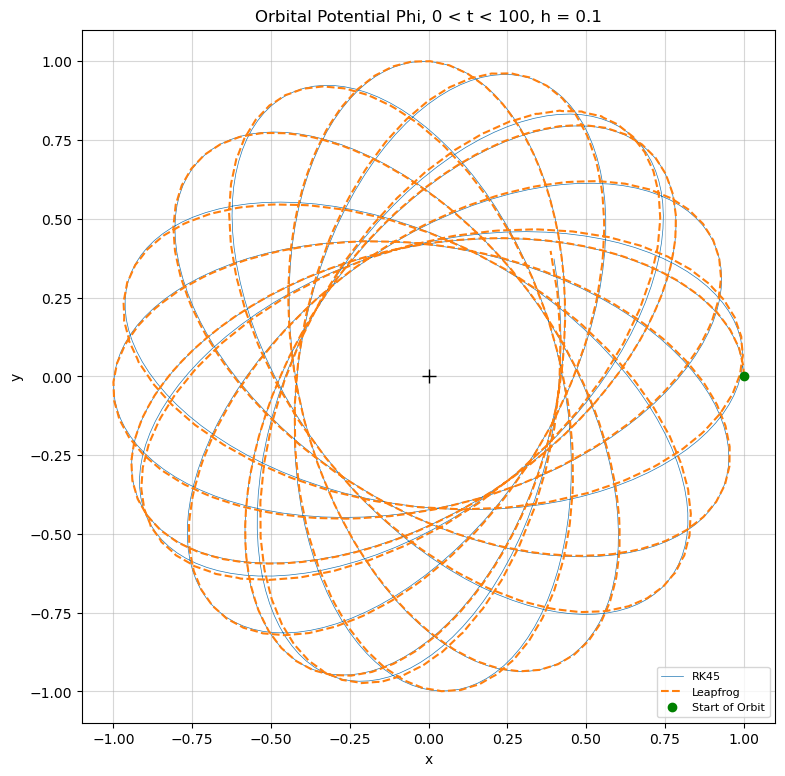

In [15]:
# 3.a) 
# Step Size 0.1

start_p = 0.0
end_p = 100.0
h_p = h_3 # interval value
N_p = int(round(((end_p - start_p)/h_p))) # truncation prevention
t_p = np.linspace(start_p, end_p, N_p+1) # 0 < t < 100, 0.01 h intervals

# Runge-Kutta: 
# (f, y_0, t_0, t_end, N) params, returns (t, y)

t_RK, y_RK = RK45(phi_orbital_2D, initial_state, start_p, end_p, N_p)
assert len(t_RK) == N_p + 1 # N + 1 for end node after N steps, no off by 1
results_RK = (t_RK, y_RK) # container for results after funct calls
    

# Leapfrog: 
# # (f, y_0, t_0, t_end, N) params, returns (t, y)

t_LF, y_LF = Leapfrog(phi_orbital_2D, initial_state, start_p, end_p, N_p)
assert len(t_LF) == N_p + 1 # N + 1 for end node after N steps, no off by 1
results_RK = (t_LF, y_LF) # container for results after funct calls

# Plotting:

fig, ax = plt.subplots(figsize=(12,9))

ax.plot(y_RK[:, 0], y_RK[:,1], label="RK45", lw=0.5)
ax.plot(y_LF[:, 0], y_LF[:,1], "--", label="Leapfrog", lw=1.5)
ax.plot(0, 0, "k+", ms=10)
ax.plot(y_RK[0, 0], y_RK[0, 1], "go", ms=6, label="Start of Orbit")

ax.set_aspect("equal")
ax.set_xlabel("x")
ax.set_ylabel("y")
ax.set_title(f"Orbital Potential Phi, 0 < t < 100, h = {h_p}")
ax.grid(True, alpha=0.5)
ax.legend(fontsize=8, loc="lower right")
plt.show()


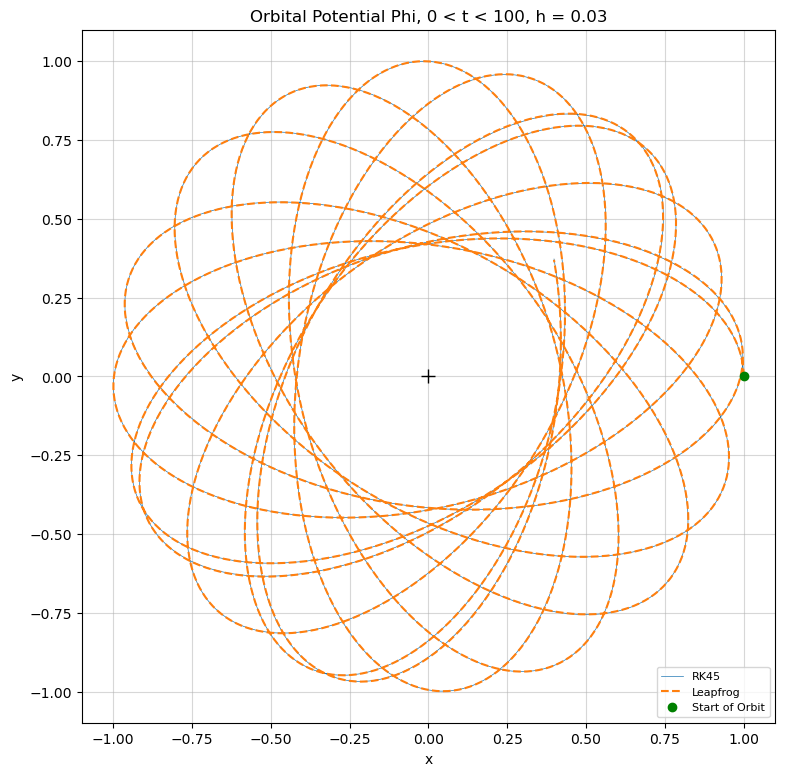

In [16]:
# 3.a) 
# Step Size 0.03

start_p = 0.0
end_p = 100.0
h_p = h_4 # interval value
N_p = int(round(((end_p - start_p)/h_p))) # truncation prevention
t_p = np.linspace(start_p, end_p, N_p+1) # 0 < t < 100, 0.01 h intervals

# Runge-Kutta: 
# (f, y_0, t_0, t_end, N) params, returns (t, y)

t_RK, y_RK = RK45(phi_orbital_2D, initial_state, start_p, end_p, N_p)
assert len(t_RK) == N_p + 1 # N + 1 for end node after N steps, no off by 1
results_RK = (t_RK, y_RK) # container for results after funct calls
    

# Leapfrog: 
# # (f, y_0, t_0, t_end, N) params, returns (t, y)

t_LF, y_LF = Leapfrog(phi_orbital_2D, initial_state, start_p, end_p, N_p)
assert len(t_LF) == N_p + 1 # N + 1 for end node after N steps, no off by 1
results_RK = (t_LF, y_LF) # container for results after funct calls

# Plotting:

fig, ax = plt.subplots(figsize=(12,9))

ax.plot(y_RK[:, 0], y_RK[:,1], label="RK45", lw=0.5)
ax.plot(y_LF[:, 0], y_LF[:,1], "--", label="Leapfrog", lw=1.5)
ax.plot(0, 0, "k+", ms=10)
ax.plot(y_RK[0, 0], y_RK[0, 1], "go", ms=6, label="Start of Orbit")

ax.set_aspect("equal")
ax.set_xlabel("x")
ax.set_ylabel("y")
ax.set_title(f"Orbital Potential Phi, 0 < t < 100, h = {h_p}")
ax.grid(True, alpha=0.5)
ax.legend(fontsize=8, loc="lower right")
plt.show()


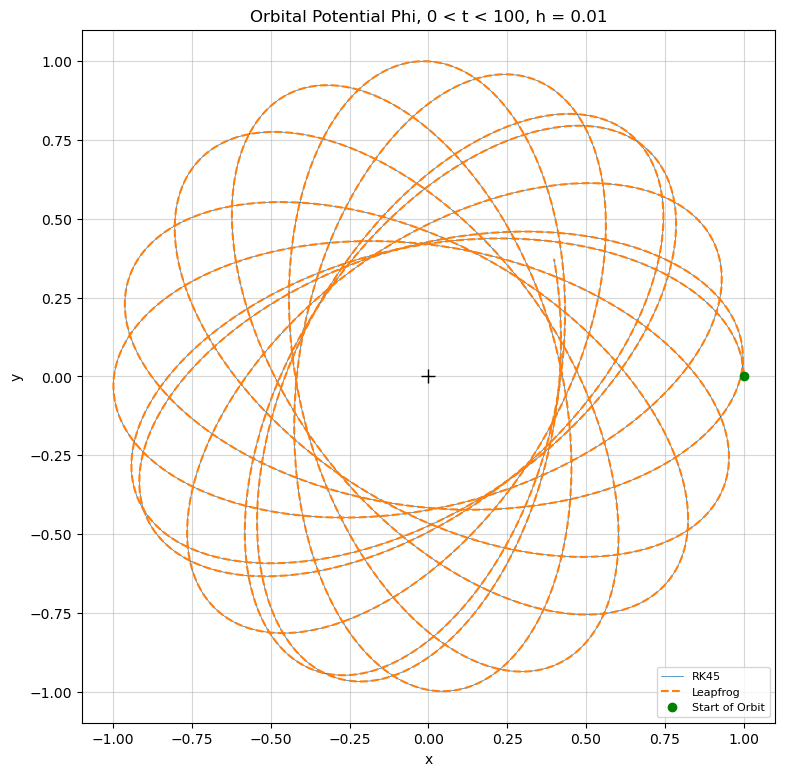

In [17]:
# 3.a) 
# Step Size 0.01

start_p = 0.0
end_p = 100.0
h_p = h_5 # interval value
N_p = int(round(((end_p - start_p)/h_p))) # truncation prevention
t_p = np.linspace(start_p, end_p, N_p+1) # 0 < t < 100, 0.01 h intervals

# Runge-Kutta: 
# (f, y_0, t_0, t_end, N) params, returns (t, y)

t_RK, y_RK = RK45(phi_orbital_2D, initial_state, start_p, end_p, N_p)
assert len(t_RK) == N_p + 1 # N + 1 for end node after N steps, no off by 1
results_RK = (t_RK, y_RK) # container for results after funct calls
    

# Leapfrog: 
# # (f, y_0, t_0, t_end, N) params, returns (t, y)

t_LF, y_LF = Leapfrog(phi_orbital_2D, initial_state, start_p, end_p, N_p)
assert len(t_LF) == N_p + 1 # N + 1 for end node after N steps, no off by 1
results_RK = (t_LF, y_LF) # container for results after funct calls

# Plotting:

fig, ax = plt.subplots(figsize=(12,9))

ax.plot(y_RK[:, 0], y_RK[:,1], label="RK45", lw=0.5)
ax.plot(y_LF[:, 0], y_LF[:,1], "--", label="Leapfrog", lw=1.5)
ax.plot(0, 0, "k+", ms=10)
ax.plot(y_RK[0, 0], y_RK[0, 1], "go", ms=6, label="Start of Orbit")

ax.set_aspect("equal")
ax.set_xlabel("x")
ax.set_ylabel("y")
ax.set_title(f"Orbital Potential Phi, 0 < t < 100, h = {h_p}")
ax.grid(True, alpha=0.5)
ax.legend(fontsize=8, loc="lower right")
plt.show()


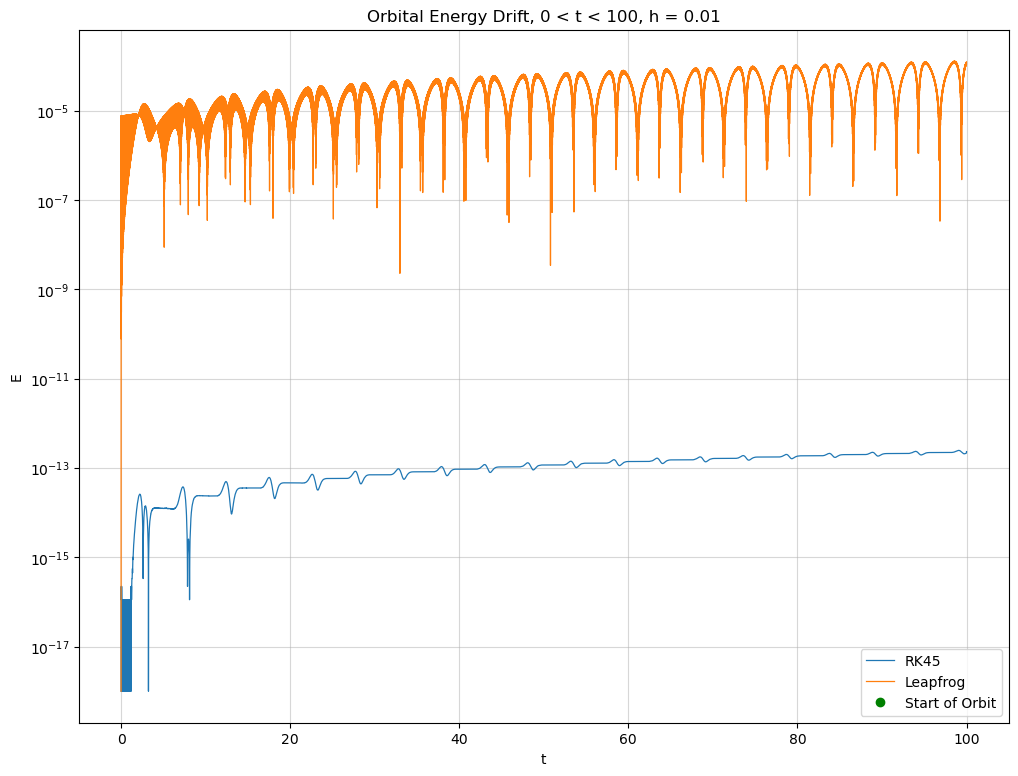

In [18]:
# 3.b) 
def Energy(pos):
    x, y, vx, vy = pos[:, 0], pos[:, 1], pos[:, 2], pos[:, 3]
    phi = (-1.0 / (1.0 + x**2 + y**2)**(1/2))

    return 0.5 * (vx**2 + vy**2) + phi

# Runge-Kutta: 
E_RK = Energy(y_RK)

# Leapfrog: 
E_LF = Energy(y_LF)

# Plotting:

fig, ax = plt.subplots(figsize=(12,9))

ax.semilogy(t_RK, np.abs(E_RK - E_RK[0]) + 1e-18, label="RK45", lw=0.9)
ax.semilogy(t_LF, np.abs(E_LF - E_LF[0]) + 1e-18, label="Leapfrog", lw=0.9)
ax.plot(t_RK[0], E_RK[0], "go", ms=6, label="Start of Orbit")

ax.set_xlabel("t")
ax.set_ylabel("E")
ax.set_title("Orbital Energy Drift, 0 < t < 100, h = 0.01")
ax.grid(True, alpha=0.5)
ax.legend()
plt.show()

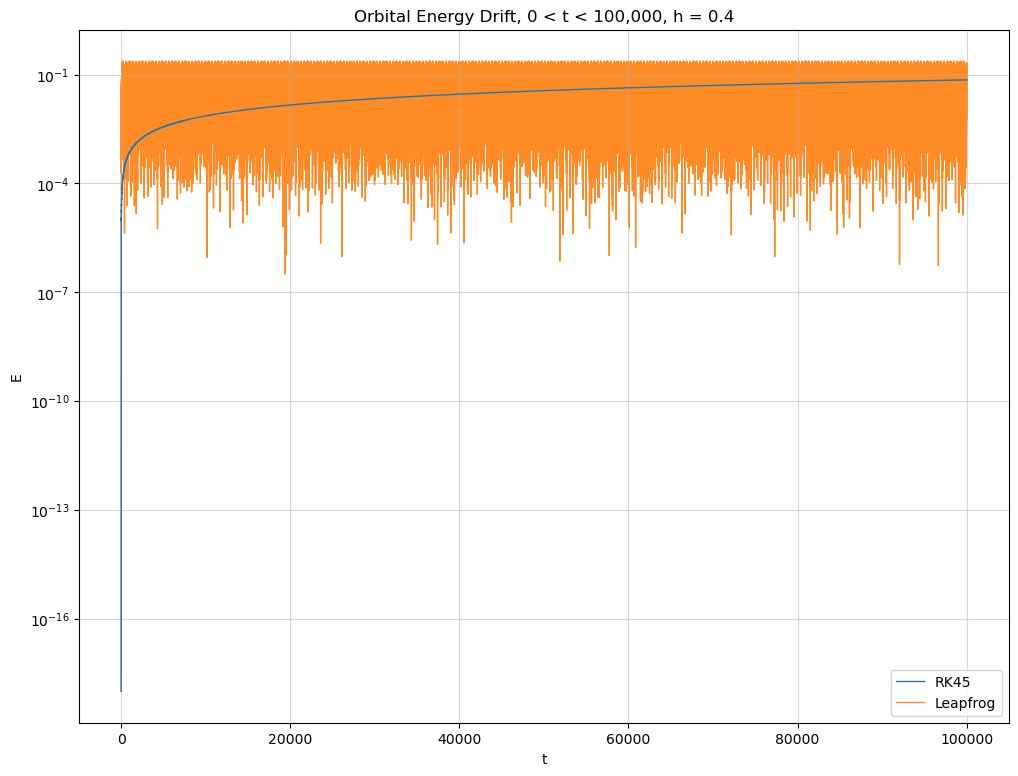

Energy Calculation runtime (RK45): 21.645893 s
Energy Calculation runtime (Leapfrog): 1.162336 s
Energy Calculation Total runtime: 23.761024 s


In [20]:
# 3.c) 
import time # wall clock import for benchmarking runtime
timestart0 = time.perf_counter() # before each integration method, and total
# elapsed = time.perf_counter() - timestart after each benchmark completes

start_p = 0.0
end_p = 100000.0
h_p = 0.4 # interval value
N_p = int(round(((end_p - start_p)/h_p))) # truncation prevention
t_p = np.linspace(start_p, end_p, N_p+1) # 0 < t < 100, 0.01 h intervals

# Runge-Kutta: 
# (f, y_0, t_0, t_end, N) params, returns (t, y)

timestart1 = time.perf_counter()
E_RK = Energy(y_RK) # re-calculating already calculated energy to time it

t_RK, y_RK = RK45(phi_orbital_2D, initial_state, start_p, end_p, N_p)
assert len(t_RK) == N_p + 1 # N + 1 for end node after N steps, no off by 1
results_RK = (t_RK, y_RK) # container for results after funct calls

elapsed1 = time.perf_counter() - timestart1

# Leapfrog: 
# # (f, y_0, t_0, t_end, N) params, returns (t, y)

timestart2 = time.perf_counter()
E_LF = Energy(y_LF)

t_LF, y_LF = Leapfrog(phi_orbital_2D, initial_state, start_p, end_p, N_p)
assert len(t_LF) == N_p + 1 # N + 1 for end node after N steps, no off by 1
results_RK = (t_LF, y_LF) # container for results after funct calls

elapsed2 = time.perf_counter() - timestart2

# Plotting Energy Drift over Time (semilogy):

fig, ax = plt.subplots(figsize=(12,9))

ax.semilogy(t_RK, np.abs(E_RK - E_RK[0]) + 1e-18, label="RK45", lw=1.0,\
            zorder=2)
ax.semilogy(t_LF, np.abs(E_LF - E_LF[0]) + 1e-18, label="Leapfrog",\
            lw=1.0, zorder=1, alpha=0.9)
ax.set_xlabel("t")
ax.set_ylabel("E")
ax.set_title("Orbital Energy Drift, 0 < t < 100,000, h = 0.4")
ax.grid(True, which="both", alpha=0.5)
ax.legend()
plt.show()

elapsed0 = time.perf_counter() - timestart0
print(f"Energy Calculation runtime (RK45): {elapsed1:.6f} s")
print(f"Energy Calculation runtime (Leapfrog): {elapsed2:.6f} s")
print(f"Energy Calculation Total runtime: {elapsed0:.6f} s")

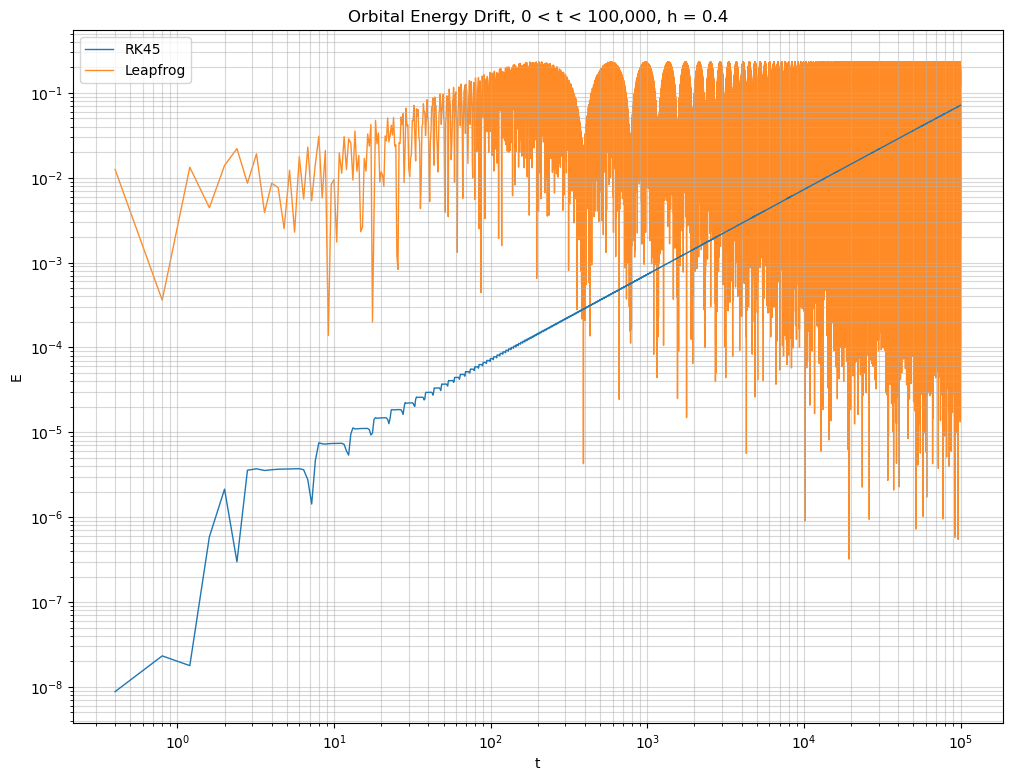

In [21]:
# Plotting Energy Drift over Time (loglog):

fig, ax = plt.subplots(figsize=(12,9))

ax.loglog(t_RK[1:], np.abs(E_RK[1:] - E_RK[0]) + 1e-18, label="RK45", lw=1.0,\
            zorder=2)
ax.loglog(t_LF[1:], np.abs(E_LF[1:] - E_LF[0]) + 1e-18, label="Leapfrog",\
          lw=1.0, zorder=1, alpha=0.9)
ax.set_xlabel("t")
ax.set_ylabel("E")
ax.set_title("Orbital Energy Drift, 0 < t < 100,000, h = 0.4")
ax.grid(True, which="both", alpha=0.5)
ax.legend()
plt.show()


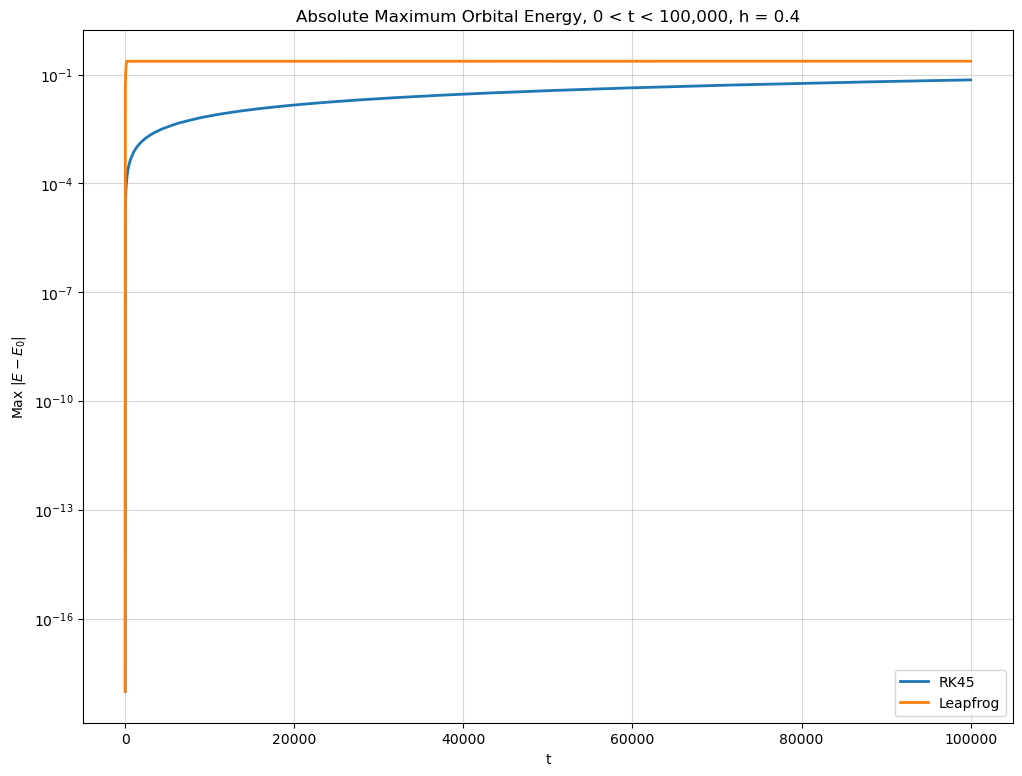

Energy Calculation runtime: 0.187888 s


In [22]:
# Plotting Max Difference in Energy from Initial Energy state over Time (semilogy):
import time # wall clock import for benchmarking runtime
timestart = time.perf_counter()
E_RK = Energy(y_RK)
R_LF = Energy(y_LF)

res = 50 # point resolution, plot one value per 50 points, to smooth curve out
fig, ax = plt.subplots(figsize=(12,9))

dE_RK = np.maximum.accumulate(np.abs(E_RK - E_RK[0]))
dE_LF = np.maximum.accumulate(np.abs(E_LF - E_LF[0]))

ax.semilogy(t_RK[::res], dE_RK[::res] + 1e-18, label="RK45", lw=2.0)
ax.semilogy(t_LF[::res], dE_LF[::res] + 1e-18, label="Leapfrog", lw=2.0)
ax.set_xlabel("t")
ax.set_ylabel(r"Max $|E - E_0|$")
ax.set_title("Absolute Maximum Orbital Energy, 0 < t < 100,000, h = 0.4")
ax.grid(True, which="both", alpha=0.5)
ax.legend()
plt.show()

elapsed = time.perf_counter() - timestart
print(f"Energy Calculation runtime: {elapsed:.6f} s")

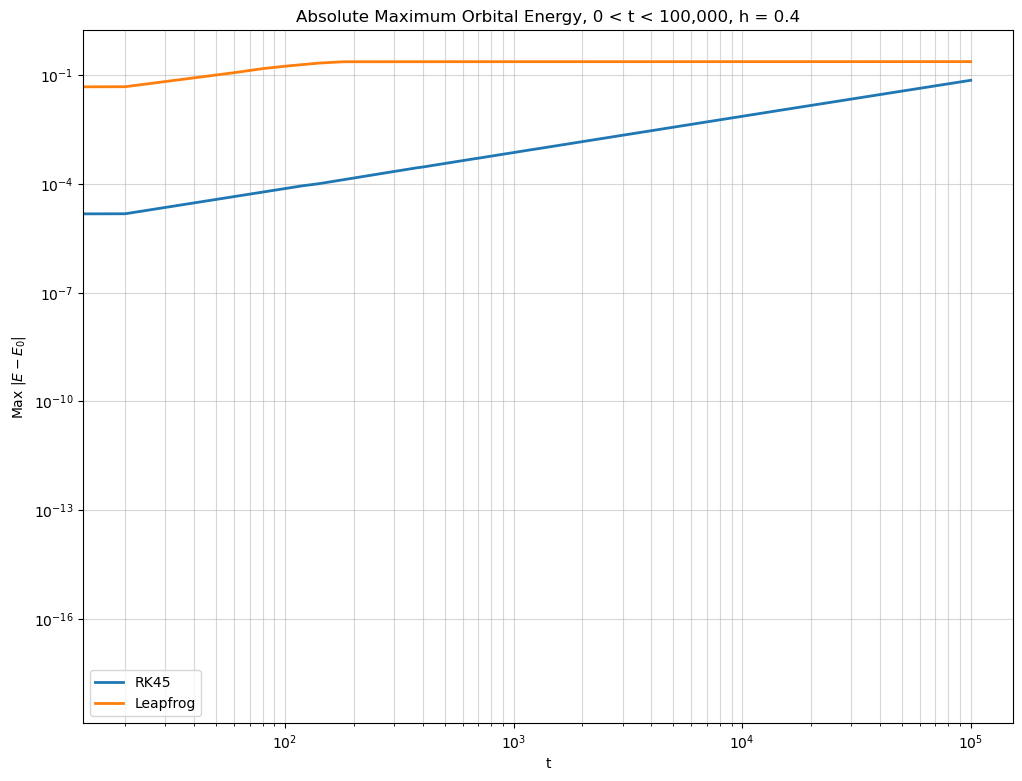

In [23]:
# Plotting Max Difference in Energy from Initial Energy state over Time (loglog):
res = 50 # point resolution, plot one value per 50 points, to smooth curve out
fig, ax = plt.subplots(figsize=(12,9))

dE_RK = np.maximum.accumulate(np.abs(E_RK - E_RK[0]))
dE_LF = np.maximum.accumulate(np.abs(E_LF - E_LF[0]))

ax.loglog(t_RK[::res], dE_RK[::res] + 1e-18, label="RK45", lw=2.0)
ax.loglog(t_LF[::res], dE_LF[::res] + 1e-18, label="Leapfrog", lw=2.0)
ax.set_xlabel("t")
ax.set_ylabel(r"Max $|E - E_0|$")
ax.set_title("Absolute Maximum Orbital Energy, 0 < t < 100,000, h = 0.4")
ax.grid(True, which="both", alpha=0.5)
ax.legend()
plt.show()

In [ ]:
# Comments on differences in behavior of E(t) methods, wall clock differences.
# Runtimes for E(t)
# Energy Calculation runtime (RK45): 22.227608 s
# Energy Calculation runtime (Leapfrog): 1.185272 s
# Energy Calculation Total runtime: 24.395034 s
# Runtime for max|E(t) - E(t(0))|
# Energy Calculation runtime: 0.186496 s
# Clearly, Leapfrog is much more efficient in the runtime, however the plots
# tell a different story. Leapfrog quickly hones in on some maximal value and
# stays there, but the fluctuations remain rampant throughout, whereas RK45
# will more stably hone in on a value over time, which more realistically 
# represents the kind of orbital or KE + PE drifts of objects over MASSIVE
# time-scales, which it does through its Scipy intrinsic handling of relative
# and absolute error terms, which it re-evaluates at a per-step basis.
# This takes a major toll on the calculation time and complexity of simulated
# values, but there is a tradeoff between initial accuracy to some value in the
# limit, and long-term stability and tracking of the evoution of the functions
# and the respective integrations of said functions over time.
# It's hard to say which is better, because of the subjective nature of their
# applications. RK45 can be used to track transient objects in the Oort Cloud,
# Leapfrog handles things like ChaNGa, which have other methods to improve on
# accuracy and stability using tree structures, exploiting the lower calculation
# intensity and finding a compromise where it gets the best of both worlds.
# Doing the absolute maximum energy difference from the start time was just to
# see how quickly, on average, each method converged to some value in the limit,
# where the integration of leapfrog essentially keeps kicking it around and
# where RK45 smoothly settles into the energy level it would arrive at in the
# limit, more accurately displaying that kind of conserved quantity as it would
# appear in nature. Leapfrog is almost like a piecewise function in my last plot